In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from src import rules

## მონაცემების ჩატვირთვა

train (4,136) სწავლისთვის, test (1,035) მხოლოდ შეფასებისთვის.
ორივეში სპამი ~12.6%-ია (stratified split).

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
print(train.shape, test.shape)

(4136, 2) (1035, 2)


## ML მოდელები

- TF-IDF თითოეულ მესიჯს აქცევს ვექტორად თ რამდენად მნიშვნელოვანია თითოეული სიტყვა და სიტყვათა წყვილი.
- Naive Bayes და Logistic Regression სწავლობენ, რომელი სიტყვები ნიშნავს სპამს.
- pipeline უზრუნველყოფს, რომ მოდელმა მხოლოდ train set-ზე ივარჯიშოს, რადგან თუ მას შეხება ექნება test set თან, მეორე ჯერზე პატერნები ნასწავლი ექნება და შედარება არასამართლიანია.


In [3]:
nb = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), MultinomialNB())
lr = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                   LogisticRegression(max_iter=1000, C=10))

nb.fit(train.text, train.y)
lr.fit(train.text, train.y)
print("trained")

trained


## Test set ის შეფასება

In [4]:
systems = {
    "Rules (v3)": rules.predict(test.text),
    "Naive Bayes": nb.predict(test.text),
    "Logistic Regression": lr.predict(test.text),
    "Never spam": np.zeros(len(test), dtype=int),
}
for name, preds in systems.items():
    print("=" * 10, name)
    print(classification_report(test.y, preds, digits=3, zero_division=0))
    print(confusion_matrix(test.y, preds))

========== Rules (v3)
              precision    recall  f1-score   support

           0      0.984     0.999     0.991       904
           1      0.991     0.885     0.935       131

    accuracy                          0.985      1035
   macro avg      0.988     0.942     0.963      1035
weighted avg      0.985     0.985     0.984      1035

[[903   1]
 [ 15 116]]
========== Naive Bayes
              precision    recall  f1-score   support

           0      0.960     1.000     0.979       904
           1      1.000     0.710     0.830       131

    accuracy                          0.963      1035
   macro avg      0.980     0.855     0.905      1035
weighted avg      0.965     0.963     0.961      1035

[[904   0]
 [ 38  93]]
========== Logistic Regression
              precision    recall  f1-score   support

           0      0.979     0.999     0.989       904
           1      0.991     0.855     0.918       131

    accuracy                          0.981      1035
   mac

## Precision–Recall მრუდი (კრიტერიუმი 2: დეტერმინისტულია თუ ალბათობითი?)

წესები დეტერმინისტულია: ერთი და იგივე მესიჯი ყოველთვის ერთსა და იმავე ქულას იღებს
(0, 1, 1.5, 2…). შედეგია მხოლოდ „სპამი" ან „არ არის სპამი", სისტემას არ გააჩნია "თავდაჯერებულობის საზომი" ML მოდელებისგან გასხვავებით. მრუდი საფეხურებიანია


ML ალბათობითია აბრუნებს P(spam)-ს, მაგალითად 0.552, ანუ ვიცით, რამდენად "თავდაჯერებულია" მოდელი.
ზღვრის (ნაგულისხმევად 0.5) შეცვლით precision/recall-ის ბალანსი თითქმის ნებისმიერ წერტილში
შეიძლება დავაყენოთ, ამიტომ მრუდი გლუვია.

note: რაც უფრო ახლოსაა მრუდი ზედა მარჯვენა კუთხესთან, მით უკეთესია სისტემა.

AP (average precision) მთელ მრუდს ერთ რიცხვად აჯამებს, 1.0 უმაღლესი შეფასება

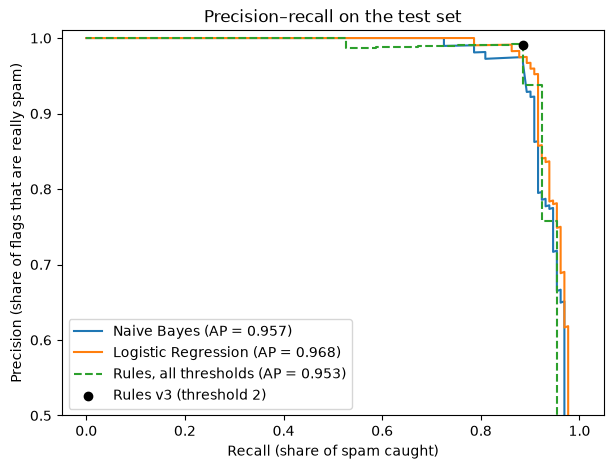

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(7, 5))

for name, model in [("Naive Bayes", nb), ("Logistic Regression", lr)]:
    proba = model.predict_proba(test.text)[:, 1]          # P(spam) per message
    p, r, _ = precision_recall_curve(test.y, proba)
    ap = average_precision_score(test.y, proba)
    ax.plot(r, p, label=f"{name} (AP = {ap:.3f})")

# Rules: their scores also form a (stepped) curve
rule_scores = rules.scores(test.text)
p, r, _ = precision_recall_curve(test.y, rule_scores)
ax.plot(r, p, drawstyle="steps-post", linestyle="--",
        label=f"Rules, all thresholds (AP = {average_precision_score(test.y, rule_scores):.3f})")

# Rules at the frozen threshold: one fixed point
ax.scatter([0.885], [0.991], color="black", zorder=5, label="Rules v3 (threshold 2)")

ax.set_xlabel("Recall (share of spam caught)")
ax.set_ylabel("Precision (share of flags that are really spam)")
ax.set_ylim(0.5, 1.01)
ax.legend(loc="lower left")
ax.set_title("Precision–recall on the test set")
plt.savefig("../pr_curve.png", dpi=200, bbox_inches="tight")
plt.show()

შედეგი: AP: LR 0.968, NB 0.957, წესები 0.953.
მაჩვენებლებით ML ოდნავ წინაა, თუმცა წესების სიზუსტე მას არ ჩამორჩება
NB სუსტი ჩანდა მხოლოდ ნაგულისხმევი 0.5 ზღვრის გამო: მისი მრუდი წესების წერტილთან ახლოს გადის.

## სად არ ეთანხმებიან სისტემები ერთმანეთს

მაგალითები სადაც ერთი სისტემა სწორია და მეორე არა.

In [6]:
r_pred = rules.predict(test.text)
l_pred = lr.predict(test.text)
mask = r_pred != l_pred
disagree = test[mask].assign(rules=r_pred[mask], lr=l_pred[mask])
print(len(disagree), "disagreements")
disagree

14 disagreements


,text,y,rules,lr
231,RECPT 1/3. You have ordered a Ringtone. Your o...,1,0,1
263,Dear Voucher Holder 2 claim your 1st class air...,1,1,0
268,Want explicit SEX in 30 secs? Ring 02073162414...,1,1,0
273,Babe: U want me dont u baby! Im nasty and have...,1,1,0
280,Hi its LUCY Hubby at meetins all day Fri & I w...,1,1,0
371,Had your contract mobile 11 Mnths? Latest Moto...,1,0,1
442,Want explicit SEX in 30 secs? Ring 02073162414...,1,1,0
453,Missed call alert. These numbers called but le...,1,1,0
579,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,1,1,0
656,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1,1,0


## White box მაგალითი

ზუსტი მიზეზები თუ რატომ არის მესიჯი სპამი ორივე შემთხვევაში


In [7]:
vec = lr.named_steps["tfidfvectorizer"]
clf = lr.named_steps["logisticregression"]
vocab = vec.get_feature_names_out()

def lr_explain(text, top=6):
    x = vec.transform([text]).toarray()[0]
    contrib = x * clf.coef_[0]
    idx = np.argsort(np.abs(contrib))[::-1][:top]
    p = lr.predict_proba([text])[0, 1]
    print(f"P(spam) = {p:.3f}")
    for i in idx:
        if contrib[i] != 0:
            print(f"  {vocab[i]:<20} {contrib[i]:+.3f}")

msg = disagree.text.iloc[0]
print(msg, "\n")
print("RULES:", rules.explain(msg), "\n")
lr_explain(msg)

RECPT 1/3. You have ordered a Ringtone. Your order is being processed... 

RULES: HAM (score 1 / threshold 2): mobile_offer 

P(spam) = 0.552
  ringtone             +1.145
  you have             +1.025
  order                +0.903
  your                 +0.699
  is                   +0.140
  order is             +0.139


## Black box მაგალითი

თითეული სიტყვის წაშლით, ვზომავთ რამდენად იცვლება იმის ალბათობა თუ რამდენად დაიჭერს ML მოდელი სპამს.
p(spam) 0.5 იდან 0.2 მდე შეიცვალა


In [8]:
def occlusion(model, text, top=6):
    base = model.predict_proba([text])[0, 1]
    words = text.split()
    effects = []
    for i, w in enumerate(words):
        without = " ".join(words[:i] + words[i+1:])
        effects.append((w, base - model.predict_proba([without])[0, 1]))
    effects.sort(key=lambda e: -abs(e[1]))
    print(f"P(spam) = {base:.3f}")
    for w, d in effects[:top]:
        print(f"  removing {w!r:<18} changes P(spam) by {-d:+.3f}")

occlusion(nb, msg)

P(spam) = 0.259
  removing 'Ringtone.'        changes P(spam) by -0.113
  removing 'being'            changes P(spam) by +0.097
  removing 'Your'             changes P(spam) by +0.090
  removing 'order'            changes P(spam) by -0.075
  removing 'is'               changes P(spam) by +0.039
  removing 'ordered'          changes P(spam) by -0.032


## ლოგიკის წყარო: რა ისწავლა მოდელმა?

ყველაზე ძლიერი სპამის და ჰემის სიტყვები Logistic Regression-ის შეფასების მიხედვით.

შედეგი: მოდელმა დამოუკიდებლად აღმოაჩინა ის key-word ები რომლებიც მე წესებად მქონდა გაწერილი.

In [12]:
order = np.argsort(clf.coef_[0])
print("Top spam words:", list(vocab[order[-20:]][::-1]))
print("\nTop ham words: ", list(vocab[order[:20]]))


Top spam words: ['txt', 'call', 'text', 'free', 'reply', 'to', 'mobile', 'www', 'uk', 'claim', '150p', 'stop', 'com', 'chat', '50', 'your', 'from', 'you have', 'won', 'now']

Top ham words:  ['my', 'me', 'ok', 'that', 'at', 'gt', 'lt', 'its', 'da', 'he', 'lt gt', 'can', 'yup', 'got', 'but', 'then', 'how', 'later', 'it', 'are you']


## ადაპტაცია (კრიტერიუმი 3)

სპამერები ფილტრების დასამარცხებლად ახალ ხრიკებს იყენებენ. მათგან სამი არის leetspeak free -> fr33
სიტყვების წერტილებად დაყოფა f.r.e.e და ციფრების დაშორება

In [13]:
import re

KEY = ["free", "win", "won", "prize", "claim", "cash", "call", "txt",
       "text", "reply", "urgent", "stop", "mobile", "ringtone"]

def dotted(t):        # free -> f.r.e.e
    return re.sub(r"\b(" + "|".join(KEY) + r")\b",
                  lambda m: ".".join(m.group()), t, flags=re.I)

def spaced_numbers(t):  # 09061701461 -> 090 617 014 61
    return re.sub(r"\d{4,}",
                  lambda m: " ".join(m.group()[i:i+3] for i in range(0, len(m.group()), 3)), t)

def leet(t):          # free -> fr33
    return t.translate(str.maketrans("eaoiEAOI", "34013401"))

def all_three(t):
    return leet(spaced_numbers(dotted(t)))

tricks = {"original": lambda t: t, "dotted words": dotted,
          "spaced numbers": spaced_numbers, "leetspeak": leet, "all three": all_three}

spam_test = test[test.y == 1].text
print(f"{'':16}{'Rules':>8}{'NB':>8}{'LR':>8}   (share of spam caught)")
for name, f in tricks.items():
    disguised = spam_test.apply(f)
    print(f"{name:16}{rules.predict(disguised).mean():8.2f}"
          f"{nb.predict(disguised).mean():8.2f}{lr.predict(disguised).mean():8.2f}")

print("\nExample:", all_three(spam_test.iloc[0]))

                   Rules      NB      LR   (share of spam caught)
original            0.89    0.71    0.85
dotted words        0.85    0.60    0.69
spaced numbers      0.73    0.70    0.85
leetspeak           0.83    0.51    0.34
all three           0.56    0.50    0.21

Example: T0d4ys V0d4f0n3 numb3rs 3nd1ng w1th 488 2 4r3 s3l3ct3d t0 4 r3c31v3 4 £350 4w4rd. 1f y0ur numb3r m4tch3s c.4.l.l 090 640 190 14 t0 r3c31v3 y0ur £350 4w4rd.


თითოეული სისტემა საკუთარ ლოგიკას ემსხვერპლა, დაშორებულმა ტელეფონის ნომრებმა regex გატეხა, ხოლო leetspeak-მა ML მოდელებისათვის სიტყვები უცნობად აქცია. მოდელებს ახლიდან სჭირდებათ გაწვრთნა, ადაპტაციის ამ კონკრეტულ შემთხვევაში წესებმა აჯობეს ML მოდელებს.

In [14]:
train_spam = train[train.y == 1]
print(f"{'added examples':>15}{'recall on all-three spam':>28}")
for n in [0, 10, 25, 50, 100, 200]:
    extra = train_spam.sample(n, random_state=0).assign(text=lambda d: d.text.apply(all_three)) if n else train_spam.iloc[:0]
    aug = pd.concat([train, extra])
    m = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                      LogisticRegression(max_iter=1000, C=10)).fit(aug.text, aug.y)
    print(f"{n:>15}{m.predict(spam_test.apply(all_three)).mean():>28.2f}")

 added examples    recall on all-three spam
              0                        0.21
             10                        0.67
             25                        0.88
             50                        0.92
            100                        0.94
            200                        0.96


სწავლებას 200 მაგალითის დამატება დასჭირდა რომ ორიგინალ მაჩვენებელზე დაბრუნებულიყო
